# 01 – Phân tích MÔ TẢ (TV3)

Cấp độ 1 trong chuỗi mô tả → chẩn đoán → dự báo → đề xuất. Logic nằm ở `src/describe.py`; notebook chỉ gọi lại và hiển thị.

**Quy ước:** lợi suất ngày thập phân, 252 phiên/năm, Sharpe/Sortino dùng `rf_annual_avg_year` (A9), mọi chỉ số tính bằng `src/metrics.py`.
**Dữ liệu:** 29 mã VN30 (kỳ 1/2020), 01/11/2018–30/09/2026, giá đã điều chỉnh. ROS ngừng giao dịch từ 11/08/2022 (NaN sau ngày đó) và được giữ lại để tránh thiên lệch sống sót.
**Danh mục 1/N** ở đây: tái cân bằng theo quý, **trước phí**, đặt tỷ trọng đều trên các mã còn giá. *Số Lớp 1 chính thức nằm ở `outputs/lop1_facts.csv`, không tính lại ở đây.*

*Kết quả là bài tập học thuật, không phải khuyến nghị đầu tư.*

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent            # notebook nằm trong notebooks/
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
import describe
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
FIG = ROOT / "outputs" / "figures"

In [2]:
res = describe.run()          # ghi lại các CSV và hình trong outputs/
P, V, R = describe.load_data()
print("Giá:", P.shape, P.index[0].date(), "→", P.index[-1].date())
print("Ô NaN theo mã (chỉ ROS):", P.isna().sum()[lambda s: s > 0].to_dict())

Giá: (1973, 29) 2018-11-01 → 2026-09-30
Ô NaN theo mã (chỉ ROS): {'ROS': 1029}


## 1. Danh mục 1/N và VN-Index theo giai đoạn

In [3]:
per = res["periods"]
tab = per.pivot(index="giai_doan", columns="danh_muc", values=["annual_return", "annual_volatility", "sharpe", "max_drawdown", "tong_loi_suat"])
order = ["toan_ky", "binh_thuong", "nam_2022"] + [y for y in per.giai_doan.unique() if y.isdigit()]
tab = tab.loc[[o for o in order if o in tab.index]]
display(tab)

annual_return             annual_volatility                        sharpe                  max_drawdown                 tong_loi_suat         
danh_muc    1/N (quý, trước phí) VN-Index 1/N (quý, trước phí) VN-Index 1/N (quý, trước phí) VN-Index 1/N (quý, trước phí) VN-Index 1/N (quý, trước phí) VN-Index
giai_doan                                                                                                                                                        
toan_ky                   0.1184   0.0864               0.2006   0.1932               0.4936   0.3548              -0.3794  -0.4034               1.3990   0.9123
binh_thuong               0.2061   0.1659               0.1974   0.1875               0.8874   0.7434              -0.3723  -0.3568               0.8020   0.6200
nam_2022                 -0.2761  -0.3310               0.2602   0.2483              -1.2479  -1.6378              -0.3794  -0.4034              -0.2733  -0.3278
2019                      0.0310   0.0773               0.1094   0.1084              -0.0574   0.3463              -0.0837  -0.0720               0.0308   0.0767
2020                      0.2013   0.1487               0.2479   0.2279               0.7521   0.6001              -0.3398  -0.3351               0.2013   0.1487
2021                      0.5235   0.3606               0.2146   0.2108               1.9700   1.4646              -0.1284  -0.1426               0.5184   0.3573
2022                     -0.2761  -0.3310               0.2602   0.2483              -1.2479  -1.6378              -0.3794  -0.4034              -0.2733  -0.3278
2023                      0.1463   0.1235               0.1820   0.1700               0.6662   0.5827              -0.1849  -0.1745               0.1445   0.1220
2024                      0.1383   0.1221               0.1390   0.1353               0.8048   0.7174              -0.0961  -0.0894               0.1371   0.1211
2025                      0.4775   0.4145               0.2151   0.2113               1.7648   1.5863              -0.1852  -0.1811               0.4707   0.4087
2026                     -0.0588  -0.0123               0.1946   0.2010              -0.4364  -0.1761              -0.1930  -0.1638              -0.0428  -0.0089

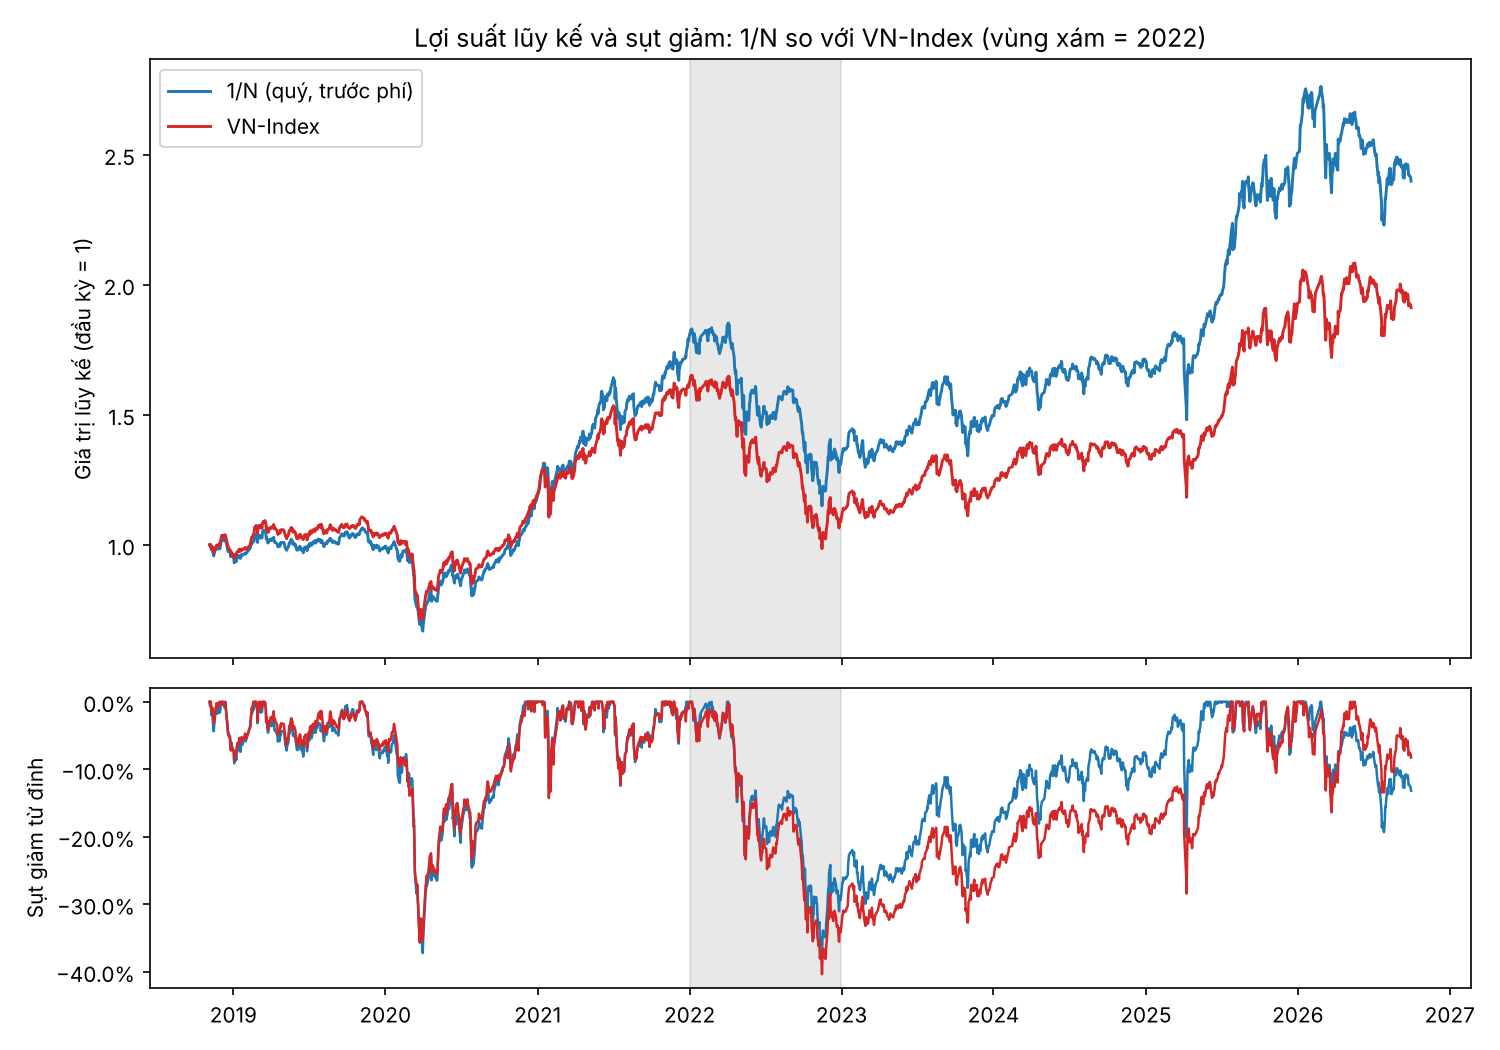

In [4]:
display(Image(FIG / "mo_ta_luy_ke_drawdown.png"))

**Nhận xét (số lấy từ bảng trên):**
- Toàn kỳ 11/2018–09/2026: 1/N có lợi suất năm hóa 11,8%, biến động 20,1%, Sharpe 0,49, sụt giảm tối đa −37,9%; VN-Index lần lượt 8,6%, 19,3%, 0,35 và −40,3%.
- Trong các năm dương lịch đủ dữ liệu (2019–2026), 1/N có lợi suất cao hơn VN-Index ở 6/8 năm (thấp hơn ở 2019 và 2026). Đây là mô tả, không giải thích được nguyên nhân.
- Có hai đợt sụt giảm sâu: COVID (đáy 03/2020) và năm 2022; cả hai danh mục đều sụt khoảng 34–40% từ đỉnh.
- Năm 2022: 1/N −27,3% và VN-Index −32,8% (tổng lợi suất cả năm). Cột `annual_return` của 2022 là năm hóa theo 249 phiên nên lệch nhẹ so với tổng lợi suất.
- Năm 2018 (chỉ 2 tháng) không đưa vào bảng vì quá ngắn.

## 2. Thống kê từng mã

In [5]:
st = res["stocks"]
full = st[st.giai_doan == "toan_ky"].set_index("ma").drop(columns="giai_doan")
display(full.sort_values("sharpe", ascending=False))
print("Số mã có Sharpe > 0 (toàn kỳ):", int((full.sharpe > 0).sum()), "/", len(full))
print("MDD trung vị:", round(full.mdd.median(), 3), "| beta với VN-Index từ", round(full.beta_vnindex.min(), 2), "đến", round(full.beta_vnindex.max(), 2))

,so_phien,ngay_cuoi_co_gia,loi_suat_nam,do_lech_chuan_nam,sharpe,sortino,mdd,beta_vnindex,tuong_quan_vnindex
ma,,,,,,,,,
FPT,1972,2026-09-30,0.2379,0.2780,0.7873,1.1758,-0.5210,0.9188,0.6386
STB,1972,2026-09-30,0.2590,0.3702,0.7176,1.0694,-0.5858,1.2404,0.6474
VIC,1972,2026-09-30,0.2396,0.3494,0.6939,1.0723,-0.6883,0.9969,0.5514
MBB,1972,2026-09-30,0.2069,0.2992,0.6678,0.9590,-0.5064,1.1730,0.7574
VPB,1972,2026-09-30,0.2113,0.3379,0.6384,0.9354,-0.4562,1.2150,0.6948
HDB,1972,2026-09-30,0.2027,0.3173,0.6358,0.9323,-0.4853,1.0561,0.6432
REE,1972,2026-09-30,0.1820,0.2986,0.5983,0.8868,-0.3858,0.8419,0.5447
CTG,1972,2026-09-30,0.1464,0.3246,0.4812,0.6951,-0.5187,1.2256,0.7295
MWG,1972,2026-09-30,0.1438,0.3387,0.4685,0.6671,-0.5547,1.1868,0.6770


Số mã có Sharpe > 0 (toàn kỳ): 24 / 29
MDD trung vị: -0.586 | beta với VN-Index từ 0.57 đến 1.51


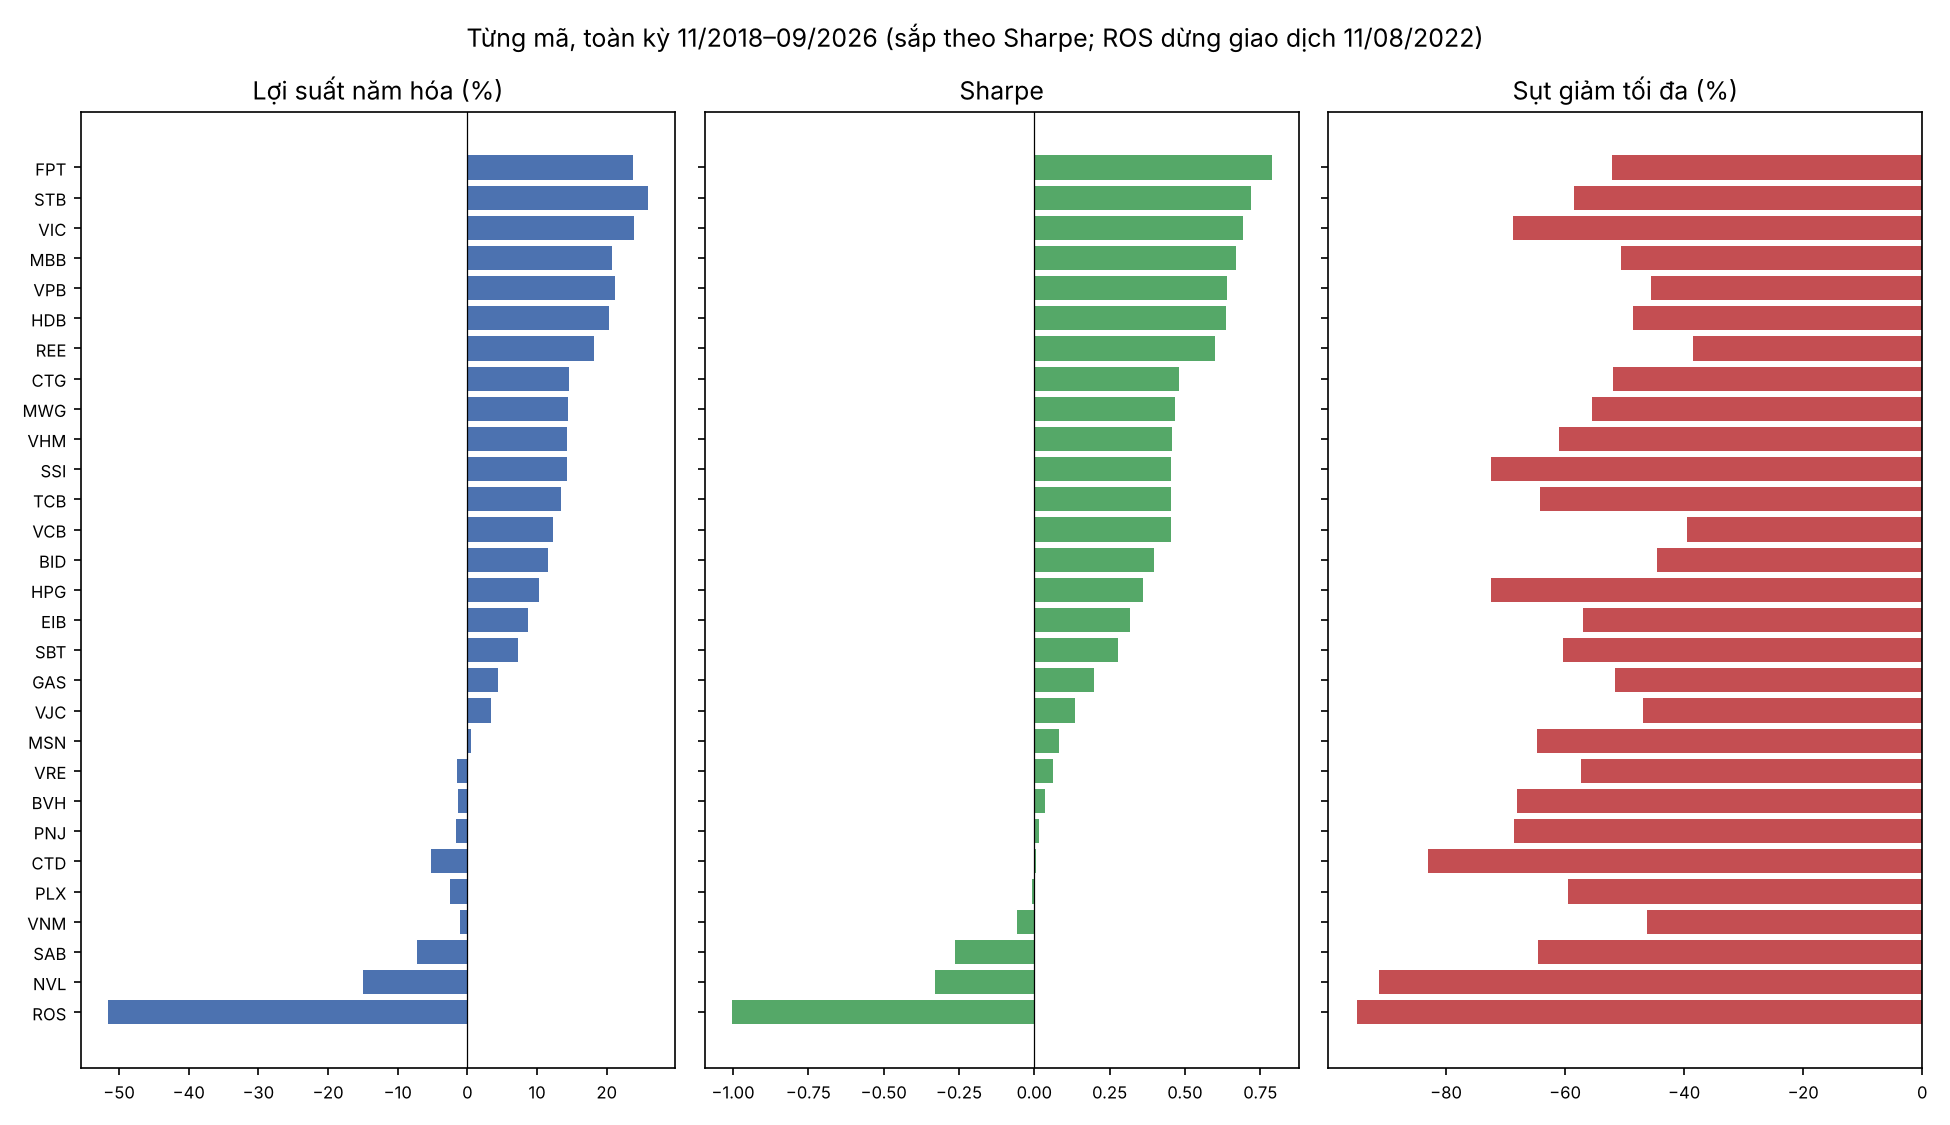

In [6]:
display(Image(FIG / "mo_ta_tung_ma.png"))

In [7]:
y22 = st[st.giai_doan == "nam_2022"].set_index("ma")
print("2022: số mã có Sharpe > 0:", int((y22.sharpe > 0).sum()), "/", len(y22), "| MDD trung vị:", round(y22.mdd.median(), 3))
display(y22.sort_values("sharpe")[["so_phien", "loi_suat_nam", "do_lech_chuan_nam", "sharpe", "mdd", "beta_vnindex"]].head(5))

2022: số mã có Sharpe > 0: 7 / 29 | MDD trung vị: -0.477


,so_phien,loi_suat_nam,do_lech_chuan_nam,sharpe,mdd,beta_vnindex
ma,,,,,,
NVL,249,-0.8496,0.4217,-4.3456,-0.8461,0.5062
ROS,150,-0.9415,0.7980,-3.1871,-0.8656,1.3610
CTD,249,-0.7039,0.5776,-1.8746,-0.7782,1.4602
VIC,249,-0.4381,0.3273,-1.7060,-0.4938,0.5687
SSI,249,-0.6262,0.5589,-1.5417,-0.7098,1.7176


**Nhận xét:**
- 24/29 mã có Sharpe dương trong toàn kỳ; tốt nhất là FPT (Sharpe 0,79, lợi suất 23,8%/năm). Kém nhất: ROS (−51,6%/năm, dừng giao dịch 11/08/2022, MDD −95%), NVL (−15,0%/năm, MDD −91%), SAB (−7,2%/năm). Lợi suất năm hóa của ROS tính trên 943 phiên có giá.
- Sụt giảm tối đa của từng mã rất lớn (trung vị −58,6%, phần lớn mã từng mất hơn một nửa giá trị từ đỉnh), trong khi danh mục 1/N chỉ −37,9%: đa dạng hóa giảm đáng kể sụt giảm nhưng không loại bỏ được.
- Năm 2022 chỉ có 7/29 mã có Sharpe dương; NVL, ROS, CTD thua nặng nhất (lợi suất năm hóa lần lượt −85%, −94%, −70%).

## 3. Tương quan giữa các mã (toàn kỳ)

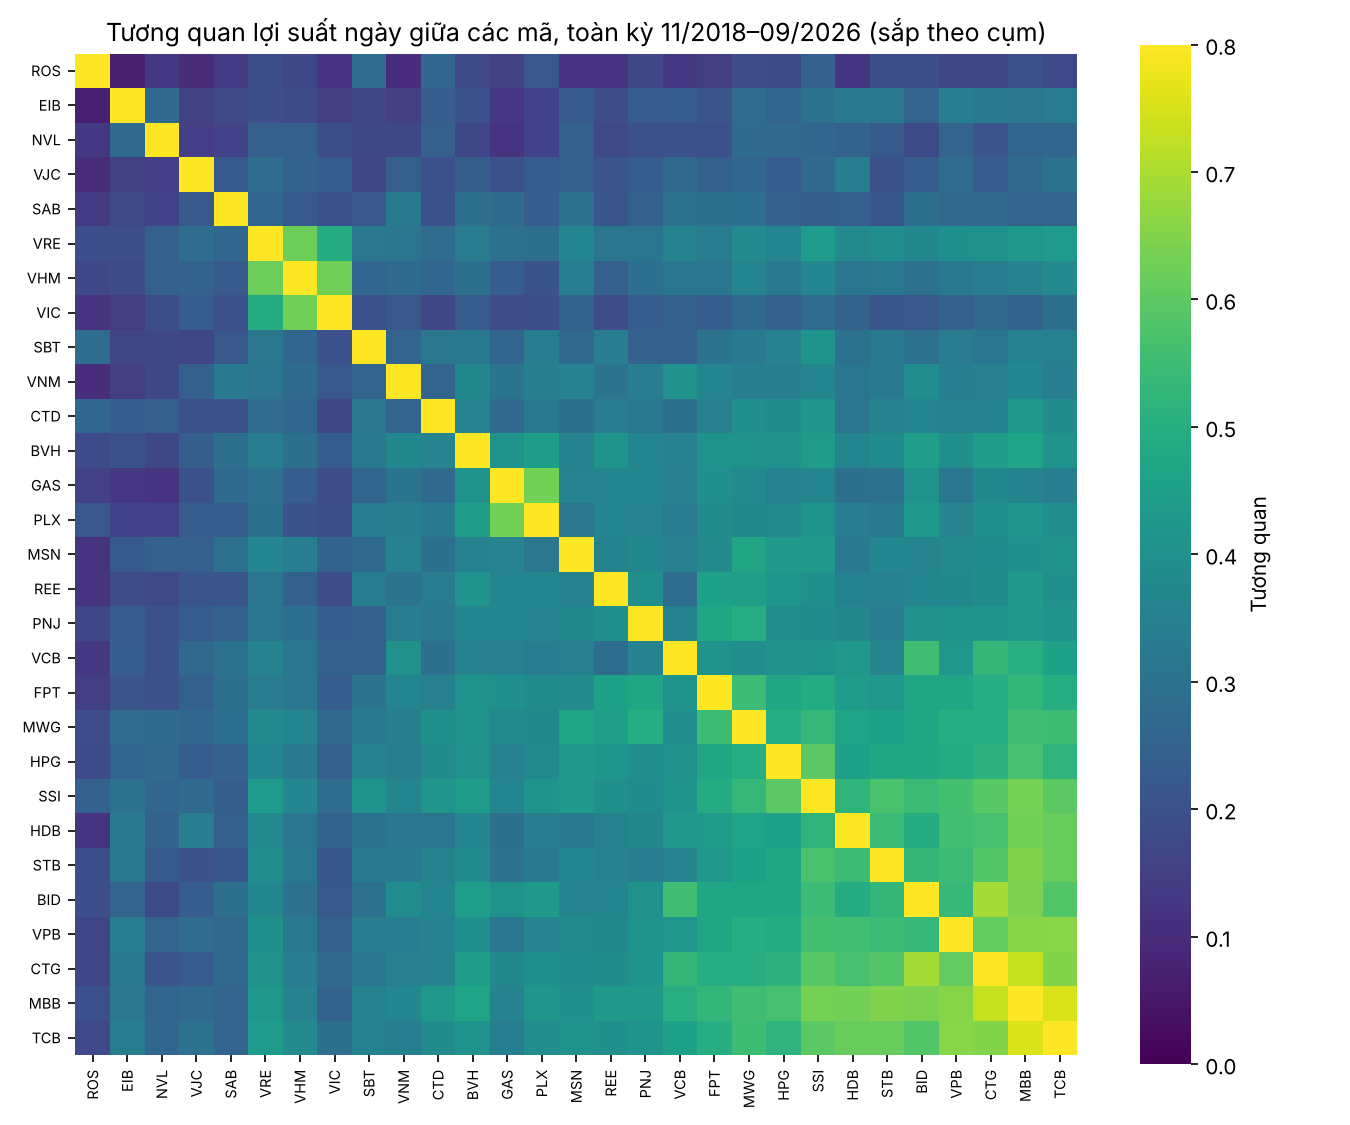

Tương quan đôi trung bình toàn kỳ: 0.337
Nhóm ngân hàng + chứng khoán (9 mã): 0.57
MBB–TCB: 0.76 | VIC–VHM: 0.63 | GAS–PLX: 0.63 | ROS–MBB: 0.19


In [8]:
display(Image(FIG / "mo_ta_heatmap_toan_ky.png"))
C = res["corr"]
iu = np.triu_indices(len(C), 1)
print("Tương quan đôi trung bình toàn kỳ:", round(float(np.nanmean(C.values[iu])), 3))
bank = ["MBB", "TCB", "CTG", "BID", "VPB", "STB", "HDB", "SSI", "VCB"]
print("Nhóm ngân hàng + chứng khoán (9 mã):", round(float(C.loc[bank, bank].values[np.triu_indices(len(bank), 1)].mean()), 2))
print("MBB–TCB:", round(C.loc["MBB", "TCB"], 2), "| VIC–VHM:", round(C.loc["VIC", "VHM"], 2), "| GAS–PLX:", round(C.loc["GAS", "PLX"], 2), "| ROS–MBB:", round(C.loc["ROS", "MBB"], 2))

**Nhận xét:** tương quan đôi trung bình toàn kỳ khoảng 0,34. Các mã ngân hàng và chứng khoán đi cùng nhau mạnh (trung bình khoảng 0,57; MBB–TCB 0,76), nhóm VIC–VHM–VRE và cặp GAS–PLX cũng cao (khoảng 0,6). ROS, EIB, NVL, VJC, SAB tương quan thấp với phần còn lại, nên là nguồn đa dạng hóa. Điều này đáng lưu ý khi tối ưu: Min Variance và Max Sharpe có thể dồn vào các mã ít tương quan nhưng có rủi ro riêng cao (NVL, SAB).

**Hạn chế:** (1) giá điều chỉnh do TV2 kiểm tra mẫu (HPG), không kiểm tra từng mã; (2) vũ trụ cố định theo VN30 kỳ 1/2020 nên có thiên lệch sống sót còn lại ở mức nhóm (các mã bị loại khỏi VN30 sau đó không có mặt); (3) 1/N ở đây chưa tính phí, giữ ROS ở giá cuối cho đến lần tái cân bằng kế tiếp; (4) toàn bộ là mô tả liên hệ, không kết luận nhân quả.